In [13]:
import os
from google.colab import drive

# Montar o Google Drive
drive.mount('/content/drive')

# Caminho da pasta de dados
CAMINHO_DATA = '/content/drive/MyDrive/Projeto_Futebol/data'

if os.path.exists(CAMINHO_DATA):
    print("✅ Google Drive ligado! Ficheiros encontrados em:", CAMINHO_DATA)
else:
    print("⚠️ Caminho não encontrado. Ajusta a variável CAMINHO_DATA.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive ligado! Ficheiros encontrados em: /content/drive/MyDrive/Projeto_Futebol/data


# 1. Business and Data Understanding (Metodologia CRISP-ML)

## 1.1. Enquadramento e Objetivos
Nesta fase inicial, o objetivo é inspecionar e compreender a fundo o conjunto de dados de partidas de futebol. Explora-se a estrutura das tabelas, valida-se a qualidade da informação e realiza-se uma **Análise Exploratória de Dados (EDA)** completa.

Abordagem:
- **Resumo Estrutural:** Identificação de colunas, registos e tipos de dados.
- **Diagnóstico de Qualidade:** Identificação de linhas duplicadas e dados nulos.
- **Análise Univariada:** Estatísticas descritivas, Assimetria (*Skewness*) e Achatamento (*Kurtosis*).
- **Análise Bivariada:** Estudo da variável alvo `FTR` (*Full Time Result*: `H`, `D`, `A`).
- **Análise Multivariada:** Comparação de matrizes de correlação de **Pearson** e **Spearman**.

In [14]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1.2. Módulo de Carregamento dos Datasets
Esta função procura todos os ficheiros `.csv` na pasta do projeto (`data/`), junta-os num único **DataFrame global** e guarda o identificador da época correspondente.

In [15]:
def carregar_e_unificar_datasets(caminho_pasta: str):
    ficheiros_csv = sorted(glob.glob(os.path.join(caminho_pasta, "*.csv")))

    if not ficheiros_csv:
        print(f"[ERRO] Nenhum ficheiro CSV encontrado na pasta '{caminho_pasta}'.")
        return None, {}

    datasets_individuais = {}
    lista_dfs = []

    for caminho in ficheiros_csv:
        nome_f = os.path.basename(caminho)
        try:
            df_temp = pd.read_csv(caminho, encoding="utf-8")
        except UnicodeDecodeError:
            df_temp = pd.read_csv(caminho, encoding="latin1")

        df_temp["Epoca"] = nome_f.replace(".csv", "")
        datasets_individuais[nome_f] = df_temp
        lista_dfs.append(df_temp)

    df_unificado = pd.concat(lista_dfs, ignore_index=True)

    print(f"[SUCESSO] {len(ficheiros_csv)} ficheiros carregados de '{caminho_pasta}'.")
    print(f"           Total de Registos: {df_unificado.shape[0]} | Colunas: {df_unificado.shape[1]}\n")

    return df_unificado, datasets_individuais

## 1.3. Inspeção da Estrutura Geral dos Dados
Permite obter uma visão geral dos dados através da visualização das primeiras linhas, contagem dos tipos de dados e resumo técnico (`.info()`).

In [16]:
def resumo_estrutura(df: pd.DataFrame, nome_dataset: str = "Dataset Global"):
    print("=" * 70)
    print(f"1. RESUMO DA ESTRUTURA DOS DADOS: {nome_dataset}")
    print("=" * 70)
    print("\n--- Primeiras 5 linhas ---")
    print(df.head())

    print("\n--- Contagem dos Tipos de Dados ---")
    print(df.dtypes.value_counts())

    print("\n--- Detalhe das Colunas e Tipos (.info()) ---")
    df.info()
    print("\n")

## 1.4. Análise da Qualidade dos Dados (Nulos e Duplicados)
Avalia a presença de registos duplicados e calcula a percentagem e contagem absoluta de valores omissos (*missing values*) por coluna.

In [17]:
def analisar_qualidade_dados(df: pd.DataFrame):
    print("=" * 70)
    print("2. ANÁLISE DE QUALIDADE DOS DADOS (NULOS E DUPLICADOS)")
    print("=" * 70)

    duplicados = df.duplicated().sum()
    print(f"Linhas duplicadas encontradas: {duplicados}")

    nulos_col = df.isnull().sum()
    perc_nulos = (nulos_col / len(df)) * 100

    relatorio_nulos = (
        pd.DataFrame({"Valores_Nulos": nulos_col, "Percentagem_%": perc_nulos})
        .query("Valores_Nulos > 0")
        .sort_values(by="Valores_Nulos", ascending=False)
    )

    if relatorio_nulos.empty:
        print("Não foram encontrados valores nulos.")
    else:
        print("\nTop 15 Colunas com Mais Valores Ausentes:")
        print(relatorio_nulos.head(15))
    print("\n")

## 1.5. Análise Univariada e Estatística Descritiva Avançada
Calcula métricas descritivas (média, desvio padrão, min, max) e métricas de forma da distribuição: **Skewness (Assimetria)** e **Kurtosis (Achatamento)**.

In [18]:
def estatisticas_descritivas_completas(df: pd.DataFrame):
    print("=" * 70)
    print("3. ESTATÍSTICAS DESCRITIVAS E EDA AVANÇADA")
    print("=" * 70)

    colunas_num = df.select_dtypes(include=[np.number])

    print("\n--- Variáveis Numéricas (Resumo Clássico) ---")
    print(colunas_num.describe().T[["mean", "std", "min", "50%", "max"]].head(15))

    print("\n--- Estatística Avançada: Skewness (Assimetria) e Kurtosis ---")
    estat_avancadas = pd.DataFrame(
        {"Skewness (Assimetria)": colunas_num.skew(), "Kurtosis": colunas_num.kurt()}
    )
    print(estat_avancadas.head(15))

    colunas_cat = df.select_dtypes(include=["object", "category"]).columns
    if len(colunas_cat) > 0:
        print("\n--- Variáveis Categóricas / Texto ---")
        print(df.describe(include=["object", "category"]).T.head(10))
    print("\n")

## 1.6. Análise Bivariada: Variável Alvo (`FTR`)
Analisa a distribuição do resultado final das partidas (`H`: Casa, `D`: Empate, `A`: Visitante) através de frequências e gráficos visuais.

In [19]:
def analisar_variavel_alvo(df: pd.DataFrame, coluna_alvo: str = "FTR"):
    print("=" * 70)
    print(f"4. ANÁLISE DA VARIÁVEL ALVO: '{coluna_alvo}'")
    print("=" * 70)

    if coluna_alvo not in df.columns:
        print(f"A coluna '{coluna_alvo}' não existe no dataset.\n")
        return

    df_valido = df.dropna(subset=[coluna_alvo])
    contagem = df_valido[coluna_alvo].value_counts()
    percentagem = df_valido[coluna_alvo].value_counts(normalize=True) * 100

    print(pd.DataFrame({"Total Jogos": contagem, "Percentagem_%": percentagem}))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.countplot(
        x=coluna_alvo, data=df_valido, order=["H", "D", "A"],
        palette="viridis", ax=axes[0], hue=coluna_alvo, legend=False
    )
    axes[0].set_title("Distribuição do Resultado Final (FTR)")
    axes[0].set_xlabel("Resultado")
    axes[0].set_ylabel("Quantidade de Jogos")

    axes[1].pie(
        contagem, labels=contagem.index, autopct="%1.1f%%",
        colors=sns.color_palette("viridis", 3), startangle=90
    )
    axes[1].set_title("Proporção dos Resultados")

    plt.tight_layout()
    plt.show()
    print("\n")

## 1.7. Análise Multivariada: Pearson vs Spearman
Compara a correlação linear (**Pearson**) com a correlação monotónica (**Spearman**) para identificar interdependências entre as estatísticas do jogo.

In [20]:
def analisar_correlacoes_completas(df: pd.DataFrame):
    print("=" * 70)
    print("5. ANÁLISE MULTIVARIADA DE CORRELAÇÃO (PEARSON VS SPEARMAN)")
    print("=" * 70)

    colunas_chave = [
        "FTHG", "FTAG", "HTHG", "HTAG", "HS", "AS", "HST", "AST",
        "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR"
    ]
    colunas_presentes = [c for c in colunas_chave if c in df.columns]

    if len(colunas_presentes) > 1:
        df_corr = df[colunas_presentes]
        fig, axes = plt.subplots(1, 2, figsize=(18, 7))

        sns.heatmap(df_corr.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar=False)
        axes[0].set_title("Correlação de Pearson (Linear)")

        sns.heatmap(df_corr.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], cbar=False)
        axes[1].set_title("Correlação de Spearman (Monotónica)")

        plt.tight_layout()
        plt.show()
    else:
        print("Métricas de jogo insuficientes para correlação.")
    print("\n")

## 1.8. Pipeline de Execução do Notebook 1
Executa sequencialmente a unificação e os diagnósticos de Análise Exploratória.

[SUCESSO] 23 ficheiros carregados de '/content/drive/MyDrive/Projeto_Futebol/data'.
           Total de Registos: 24060 | Colunas: 151

1. RESUMO DA ESTRUTURA DOS DADOS: Dataset Unificado

--- Primeiras 5 linhas ---
  Div      Date  HomeTeam       AwayTeam  FTHG  FTAG FTR  HTHG  HTAG HTR  ...  \
0  E0  19/08/00  Charlton       Man City     4     0   H     2     0   H  ...   
1  E0  19/08/00   Chelsea       West Ham     4     2   H     1     0   H  ...   
2  E0  19/08/00  Coventry  Middlesbrough     1     3   A     1     1   D  ...   
3  E0  19/08/00     Derby    Southampton     2     2   D     1     2   A  ...   
4  E0  19/08/00     Leeds        Everton     2     0   H     2     0   H  ...   

   MaxCAHH MaxCAHA  AvgCAHH  AvgCAHA  Home_Golos_Marcados_L5  \
0      NaN     NaN      NaN      NaN                     NaN   
1      NaN     NaN      NaN      NaN                     NaN   
2      NaN     NaN      NaN      NaN                     NaN   
3      NaN     NaN      NaN      NaN     

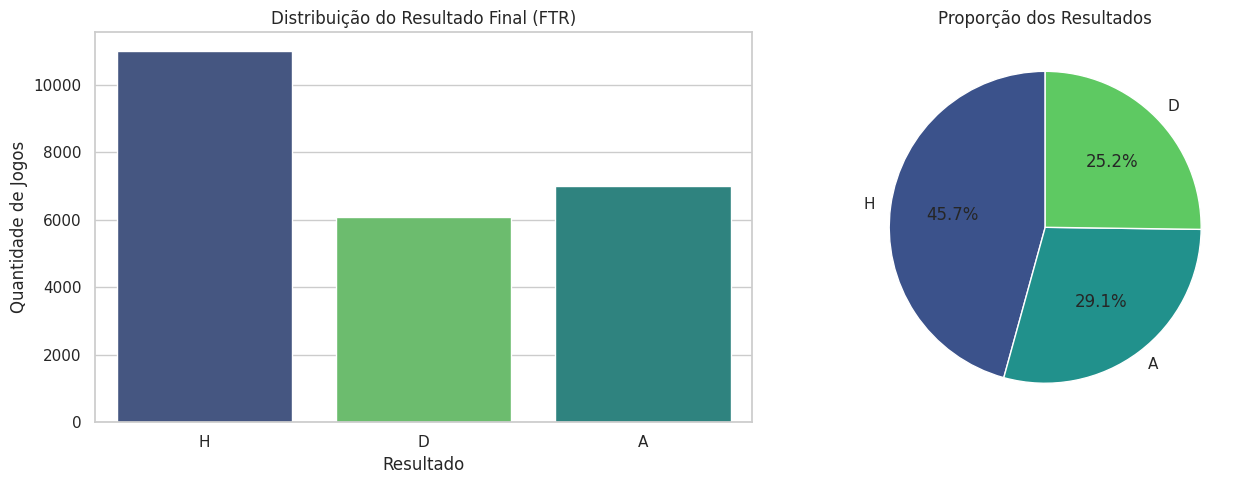



5. ANÁLISE MULTIVARIADA DE CORRELAÇÃO (PEARSON VS SPEARMAN)


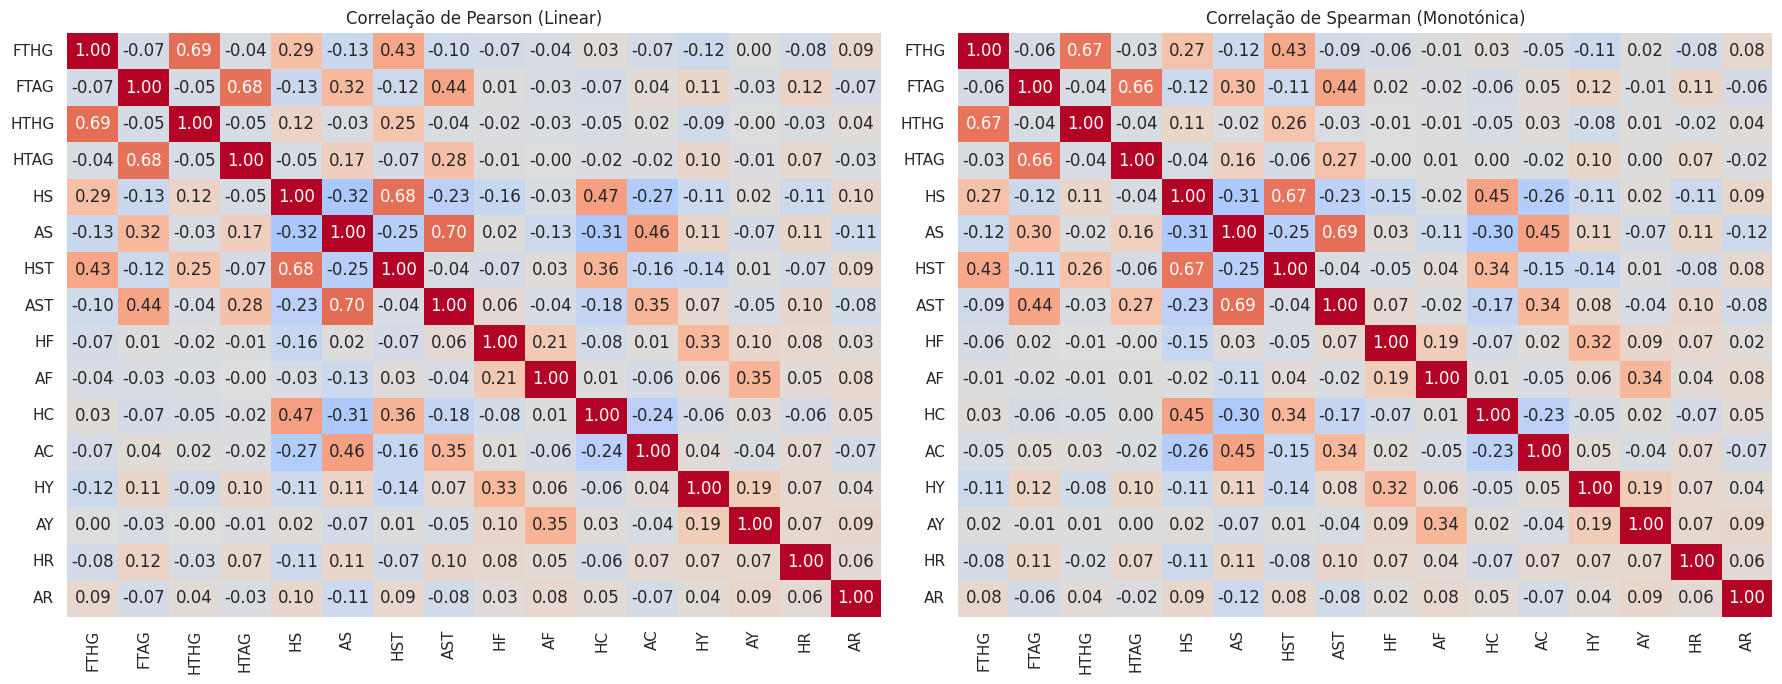

In [21]:
df_futebol, datasets_individuais = carregar_e_unificar_datasets(CAMINHO_DATA)

if df_futebol is not None:
    resumo_estrutura(df_futebol, nome_dataset="Dataset Unificado")
    analisar_qualidade_dados(df_futebol)
    estatisticas_descritivas_completas(df_futebol)
    analisar_variavel_alvo(df_futebol, coluna_alvo="FTR")
    analisar_correlacoes_completas(df_futebol)